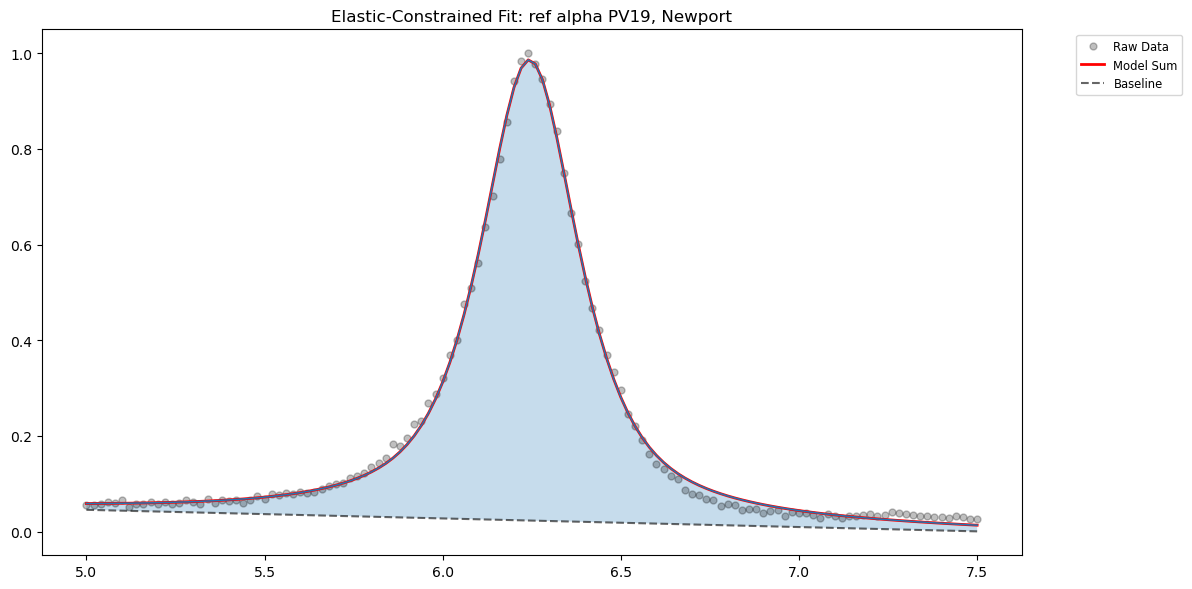

Reference ref alpha PV19, Newport has a scattering potency of: 4986.27


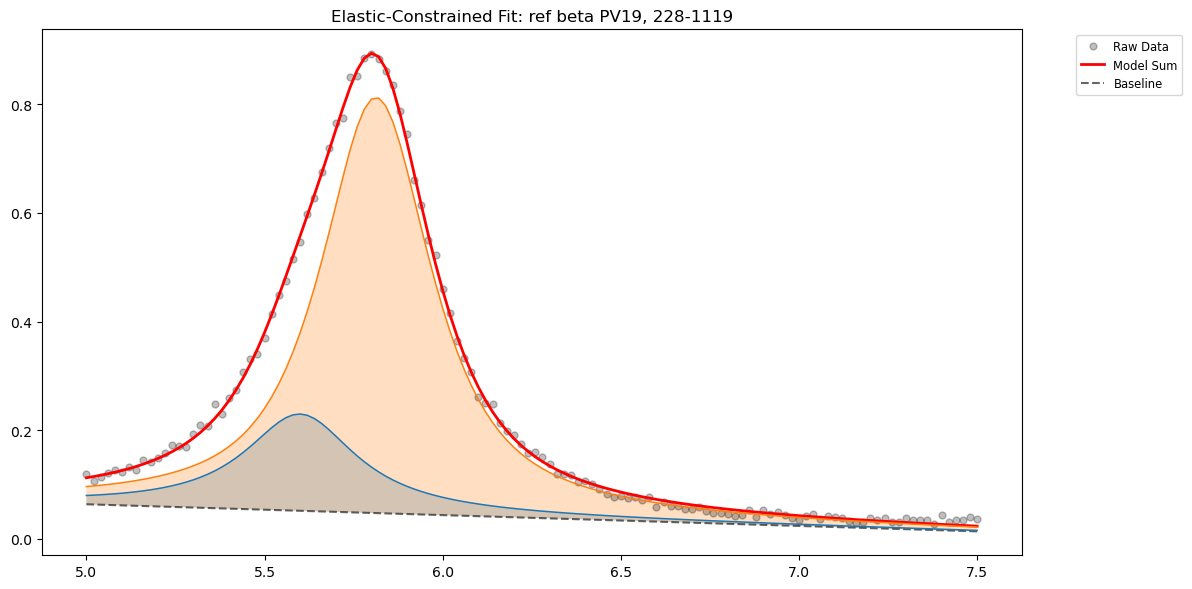

Reference ref beta PV19, 228-1119 has a scattering potency of: 2645.45


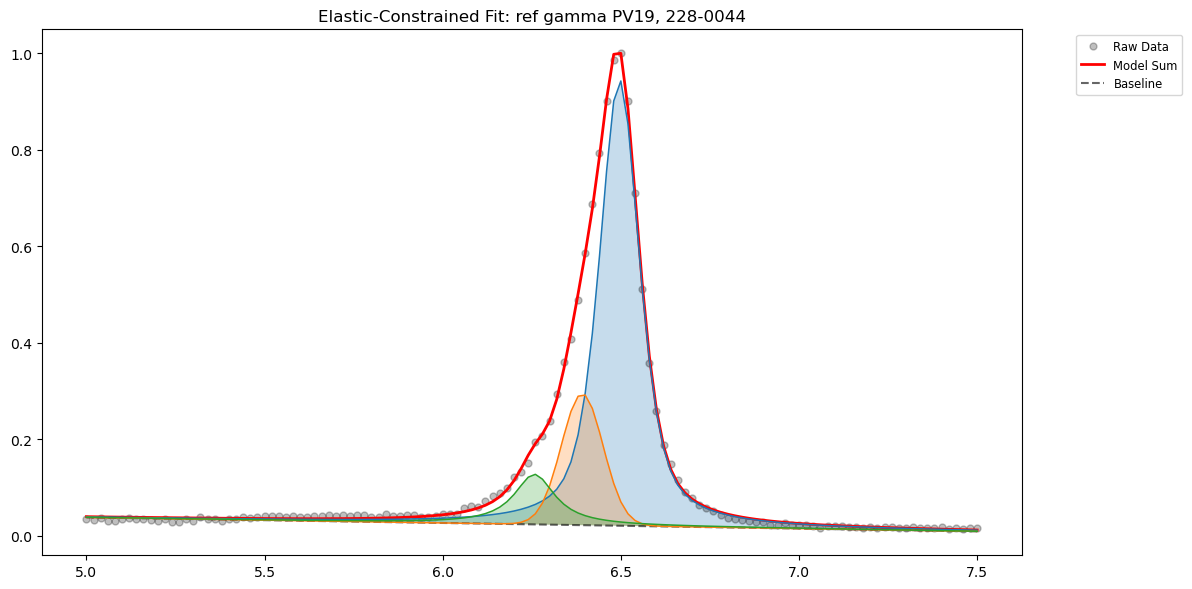

Reference ref gamma PV19, 228-0044 has a scattering potency of: 3506.72


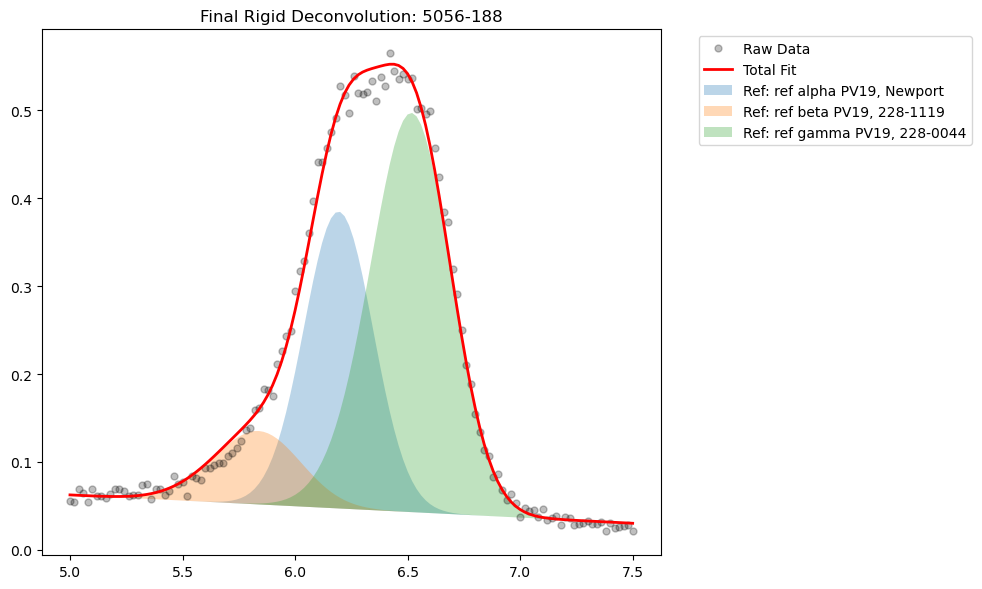

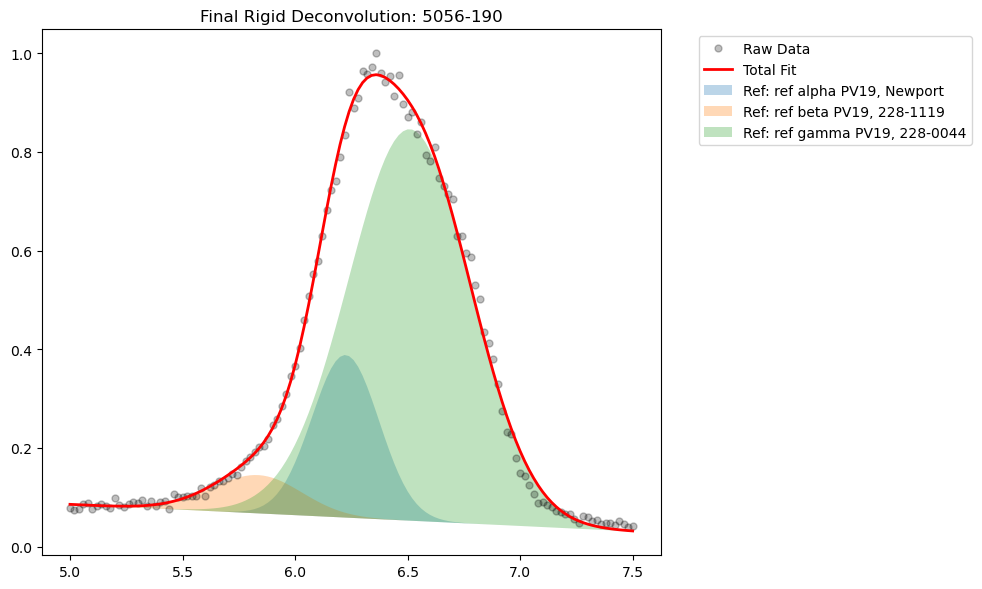

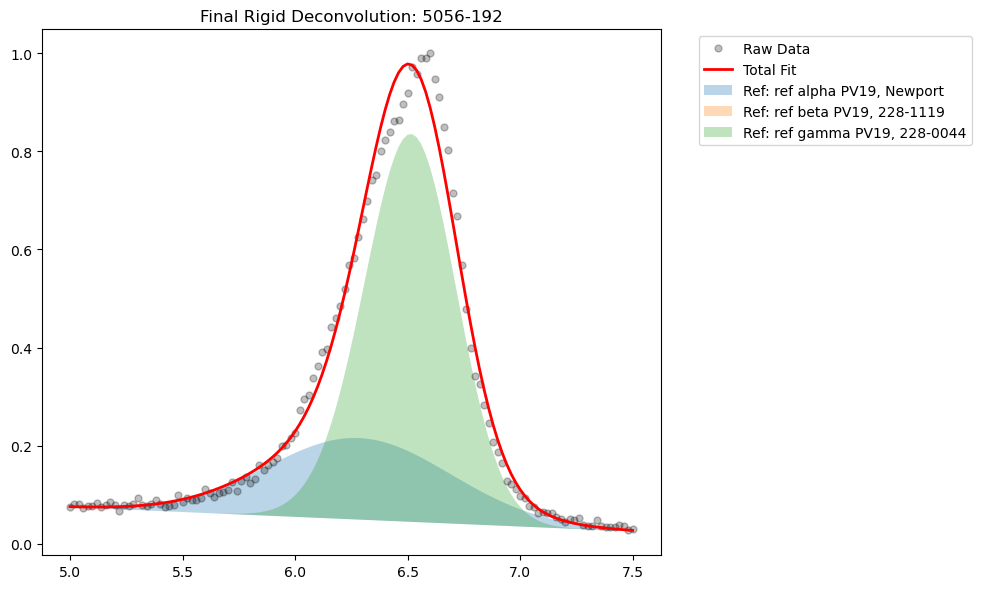

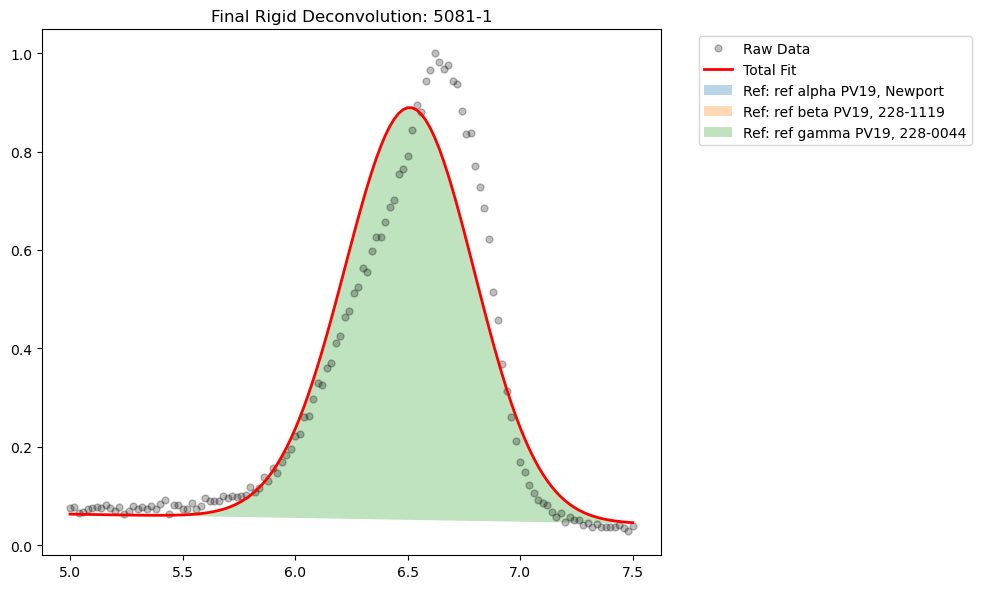

All graphs saved to: P:\RandD\Jason Orlando\XRD\AA delete this\deconvolution\XRD Voigt graphical peak deconvolution summary.pdf
Quantification exported to: P:\RandD\Jason Orlando\XRD\AA delete this\deconvolution\XRD Voigt peak deconvolution summary.csv



,Sample,"ref alpha PV19, Newport (%)","ref beta PV19, 228-1119 (%)","ref gamma PV19, 228-0044 (%)"
0,5056-188,25.97,15.39,58.64
1,5056-190,12.74,7.58,79.68
2,5056-192,22.60,0.00,77.40
3,5081-1,0.00,0.00,100.00


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from pathlib import Path
from scipy.signal import savgol_filter, find_peaks
from lmfit.models import GaussianModel, PseudoVoigtModel, LinearModel
from matplotlib.backends.backend_pdf import PdfPages
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# -------------------------------------------** fitting region **----------------------------------
XRD_REQ = (r"AA delete this")                                                 # Alter this to file location
fit_peak = 'v'                                                                # v for voigt / else for guassian
lower_bound = 5                                                               # lower bond for area of interest                                     
upper_bound = 7.5                                                             # upper bond for area of interest
# -------------------------------------------** fitting reference peaks **----------------------------------
center_tolerance = 0.2                                                        # tolerance for finding peak center for references (default 0.2)
min_distance = 10                                                             # threshold for peak resolution of reference peaks
elastic_sigma = 0.01                                                          # ability for the fitted peaks to stretch and contract when fitting the references (default 0.01)
# -------------------------------------------** fitting samples to ref peaks **----------------------------------
sample_peak_sigma_min = 0.01                                                  # default is 0.01
sample_peak_sigma_max = 0.5                                                   # default is 0.5
sample_peak_shift = 0.05                                                      # default is 0.05
# ---------------------------------------------------------------------------------------------------------------

folder = Path(fr'P:\RandD\Jason Orlando\XRD\{XRD_REQ}')
output_folder = folder / "deconvolution"
output_folder.mkdir(parents=True, exist_ok=True)
model_label = "Voigt" if fit_peak == 'v' else "Gaussian"
pdf_path = output_folder / f"XRD {model_label} graphical peak deconvolution summary.pdf"
output_path = output_folder / f"XRD {model_label} peak deconvolution summary.csv"
xrd_samples = {}
xrd_refs = {}
ref_potency = {}
normalization_values = {}

with PdfPages(pdf_path) as pdf:
    for file in folder.glob("*.csv"):
        raw_name = file.stem
        clean_name = raw_name.strip(" _-")
        
        df = pd.read_csv(file, sep='\t', names=['2Theta', 'Intensity'], header=None)
        df['2Theta'] = pd.to_numeric(df['2Theta'], errors='coerce')
        df['Intensity'] = pd.to_numeric(df['Intensity'], errors='coerce').fillna(0)
        i_min = df['Intensity'].min()
        i_max = df['Intensity'].max()
        normalization_values[clean_name] = i_max
        df['Intensity'] = (df['Intensity'] - i_min) / (i_max - i_min)

        filtered_df = df[df['2Theta'].between(lower_bound, upper_bound)]

        if "ref" in clean_name.lower():
            xrd_refs[clean_name] = filtered_df
        else:
            xrd_samples[clean_name] = filtered_df

    ref_library = {}
    for name, df in xrd_refs.items():
        x, y = df['2Theta'].values, df['Intensity'].values
        y_smooth = savgol_filter(y, 11, 3)
        
        clean_name = re.sub(r'[^a-zA-Z0-9_]', '_', name)
        master_sigma = f'sigma_{clean_name}'
        
        # Peak detection parameters in references
        p_val = 0.007
        indices, _ = find_peaks(y_smooth, prominence=p_val, distance=min_distance)
        model = LinearModel(prefix='bg_')
        params = model.make_params(slope=0, intercept=np.percentile(y, 3))
        params.add(master_sigma, value=0.12, min=0.05, max=0.4)
    
        def add_peak_logic(idx, p_id, current_params, current_model):
            pref = f'p{p_id}_'
            
            if fit_peak == 'v':
                peak = PseudoVoigtModel(prefix=pref)
                current_model += peak
                current_params.update(peak.make_params())
                current_params[f'{pref}fraction'].set(value=0.5, min=0, max=1)
            else:
                peak = GaussianModel(prefix=pref)
                current_model += peak
                current_params.update(peak.make_params())
                
            peak_params = peak.guess(y, x=x)
            current_params.update(peak_params)
            
            current_params[f'{pref}center'].set(value=x[idx], min=x[idx]-center_tolerance, max=x[idx]+center_tolerance)
            
            current_params[f'{pref}sigma'].set(value=0.12, min=0.05, max=0.4)
            current_params.add(f'{pref}sigma_ratio', value=1.0, min=1 - elastic_sigma, max=1 + elastic_sigma)
            current_params[f'{pref}sigma'].set(expr=f'{master_sigma} * {pref}sigma_ratio')
            
            current_params[f'{pref}amplitude'].set(min=0)
            return current_model
    
        for i, idx in enumerate(indices):
            model = add_peak_logic(idx, i, params, model)
        
        result = model.fit(y, params, x=x)
        
        # Residual Seeding (Adding the missing shoulders)
        for extra in range(2): 
            residual = y - result.best_fit
            res_smooth = savgol_filter(residual, 15, 3)
            # Look for gaps that are 2x the standard deviation of the noise
            res_indices, _ = find_peaks(res_smooth, prominence=np.std(residual)*2)
            
            if len(res_indices) > 0:
                new_idx = res_indices[np.argmax(res_smooth[res_indices])]
                model = add_peak_logic(new_idx, f'extra_{extra}', params, model)
                result = model.fit(y, params, x=x)
    
        comps = result.eval_components(x=x)
        plt.figure(figsize=(12, 6))
        plt.plot(x, y, 'ko', markersize=5, alpha=0.25, label='Raw Data')
        plt.plot(x, result.best_fit, 'r-', linewidth=2, label='Model Sum')
        plt.plot(x, comps['bg_'], 'k--', alpha=0.6, label='Baseline')
        
        final_peaks = []
        peak_keys = [k for k in comps.keys() if k != 'bg_']
        for i, pk in enumerate(peak_keys):
            c_val = result.params[f'{pk}center'].value
            s_val = result.params[f'{pk}sigma'].value
            a_val = result.params[f'{pk}amplitude'].value 
            
            p_dna = {
                        'center': c_val, 
                        'sigma': s_val, 
                        'amplitude': a_val 
                    }
            
            # Gaussian/Lorentzian mix found in the reference peaks
            if fit_peak == 'v':
                p_dna['fraction'] = result.params[f'{pk}fraction'].value
            final_peaks.append(p_dna)
            
            plt.plot(x, comps['bg_'] + comps[pk], linewidth=1.1)
            plt.fill_between(x, comps['bg_'], comps['bg_'] + comps[pk], alpha=0.25)
    
        ref_library[name] = final_peaks
        plt.title(f"Elastic-Constrained Fit: {name}")
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize='small')
        plt.tight_layout()

        pdf.savefig()
        plt.show()
        plt.close()

        total_ref_area = 0
        for pk, comp_val in comps.items():
            if pk != 'bg_':
                total_ref_area += np.trapezoid(comp_val, x) * normalization_values[name]

        ref_potency[name] = total_ref_area
        print(f"Reference {name} has a scattering potency of: {total_ref_area:.2f}")
    
    # fitting the samples to reference composite peak
    unknown_results = {}
    summary_list = []
    
    for unk_name, unk_df in xrd_samples.items():
        if unk_df.empty:
            print(f"Skipping {unk_name}: No data found between {lower_bound} and {upper_bound}")
            continue

        x_unk = unk_df['2Theta'].values
        y_unk = unk_df['Intensity'].values
        
        if np.all(np.isnan(y_unk)) or len(y_unk) == 0:
            print(f"Skipping {unk_name}: Data contains only NaNs or is empty.")
            continue

        model = LinearModel(prefix='bg_')
        params = model.make_params(slope=0, intercept=np.percentile(y_unk, 5))
        
        for ref_name, peaks in ref_library.items():
            clean_ref = re.sub(r'[^a-zA-Z0-9_]', '_', ref_name)
            
            params.add(f'scale_{clean_ref}', value=0.1, min=0)
            params.add(f'sigma_{clean_ref}', value=peaks[0]['sigma'], min= sample_peak_sigma_min, max= sample_peak_sigma_max)
            params.add(f'shift_{clean_ref}', value=0.0, min= 0 - sample_peak_shift, max= 0 + sample_peak_shift)
            
            for i, p in enumerate(peaks):
                pref = f'{clean_ref}_p{i}_'
                peak_mod = GaussianModel(prefix=pref)
                model += peak_mod
                
                params.add(f'{pref}center', expr=f'{p["center"]} + shift_{clean_ref}')
                params.add(f'{pref}sigma', expr=f'sigma_{clean_ref}')
                params.add(f'{pref}amplitude', expr=f'scale_{clean_ref} * {p["amplitude"]}')
    
        result = model.fit(y_unk, params, x=x_unk)
        comps = result.eval_components(x=x_unk)
        
        # Quantification using np.trapezoid
        phase_masses = {}
        for ref_name in ref_library.keys():
            clean_ref = re.sub(r'[^a-zA-Z0-9_]', '_', ref_name)
            phase_sum = np.zeros_like(x_unk)
            for c_name, c_val in comps.items():
                if c_name.startswith(clean_ref):
                    phase_sum += c_val
            
            raw_fitted_area = np.trapezoid(phase_sum, x_unk)
            
            potency = ref_potency.get(ref_name, 1.0)
            phase_masses[ref_name] = raw_fitted_area / potency

        total_mass = sum(phase_masses.values())
        unk_summary = {"Sample": unk_name}
        
        for name, mass in phase_masses.items():
            percent = (mass / total_mass * 100) if total_mass > 0 else 0
            unk_summary[f"{name} (%)"] = round(percent, 2)
        
        summary_list.append(unk_summary)
    
        plt.figure(figsize=(10, 6))
        plt.plot(x_unk, y_unk, 'ko', markersize=5, alpha=0.25, label='Raw Data')
        plt.plot(x_unk, result.best_fit, 'r-', linewidth=2, label='Total Fit')
        
        for ref_name in ref_library.keys():
            clean_ref = re.sub(r'[^a-zA-Z0-9_]', '_', ref_name)
            p_sum = np.zeros_like(x_unk)
            for c_name, c_val in comps.items():
                if c_name.startswith(clean_ref):
                    p_sum += c_val
            plt.fill_between(x_unk, comps['bg_'], comps['bg_'] + p_sum, alpha=0.3, label=f'Ref: {ref_name}')
    
        plt.title(f"Final Rigid Deconvolution: {unk_name}")
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        
        pdf.savefig()
        plt.show()
        plt.close()
    
summary_df = pd.DataFrame(summary_list)
summary_df.to_csv(output_path, index=False)

print(f"All graphs saved to: {pdf_path}")
print(f"Quantification exported to: {output_path}\n")
summary_df